<a href="https://colab.research.google.com/github/Mhamuda/CSEM2151-Computer_Vision/blob/main/Assignment8_Image_Denoising.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#Install required packages

In [3]:
!pip -q install torchinfo torchview scikit-image pandas openpyxl
!apt-get -qq install graphviz

#Import libraries

In [4]:
import os
import gc
import time
import math
import random
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.utils import save_image

from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity as skimage_ssim

from torchinfo import summary

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu128
CUDA available: True


#Configuration

In [5]:
# ============================================================
# PROJECT CONFIGURATION
# ============================================================

PROJECT_DIR = "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising"

# CHANGE THIS PATH ONLY
DATASET_DIR = "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Image_Denoising_Dataset"

RESULTS_DIR = os.path.join(PROJECT_DIR, "Results")
MODEL_DIR = os.path.join(PROJECT_DIR, "Saved_Models")
CSV_DIR = os.path.join(RESULTS_DIR, "CSV")
FIGURE_DIR = os.path.join(RESULTS_DIR, "Figures")
ARCH_DIR = os.path.join(RESULTS_DIR, "Architectures")
OUTPUT_DIR = os.path.join(RESULTS_DIR, "Denoised_Images")

for directory in [
    PROJECT_DIR,
    RESULTS_DIR,
    MODEL_DIR,
    CSV_DIR,
    FIGURE_DIR,
    ARCH_DIR,
    OUTPUT_DIR
]:
    os.makedirs(directory, exist_ok=True)

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

# ============================================================
# DATA SETTINGS
# ============================================================

IMAGE_SIZE = 128

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Gaussian noise levels required by assignment
NOISE_LEVELS = [15, 25, 50]

# During training, sigma will randomly be selected
# from the above three noise levels.

BATCH_SIZE = 16
NUM_WORKERS = 2

# ============================================================
# TRAINING SETTINGS
# ============================================================

EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5

print("Project directory:", PROJECT_DIR)

Device: cuda
Project directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising


#Collect all clean images

In [6]:
SUPPORTED_EXTENSIONS = (
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
)

all_image_files = []

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower().endswith(SUPPORTED_EXTENSIONS):
            all_image_files.append(os.path.join(root, file))

all_image_files = sorted(all_image_files)

print("Total images found:", len(all_image_files))

assert len(all_image_files) > 0, (
    f"No images found in:\n{DATASET_DIR}\n"
    "Please check DATASET_DIR."
)

print("\nFirst 5 image paths:")
for path in all_image_files[:5]:
    print(path)

Total images found: 500

First 5 image paths:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Image_Denoising_Dataset/100007.jpg
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Image_Denoising_Dataset/100039.jpg
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Image_Denoising_Dataset/100075.jpg
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Image_Denoising_Dataset/100080.jpg
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Image_Denoising_Dataset/100098.jpg


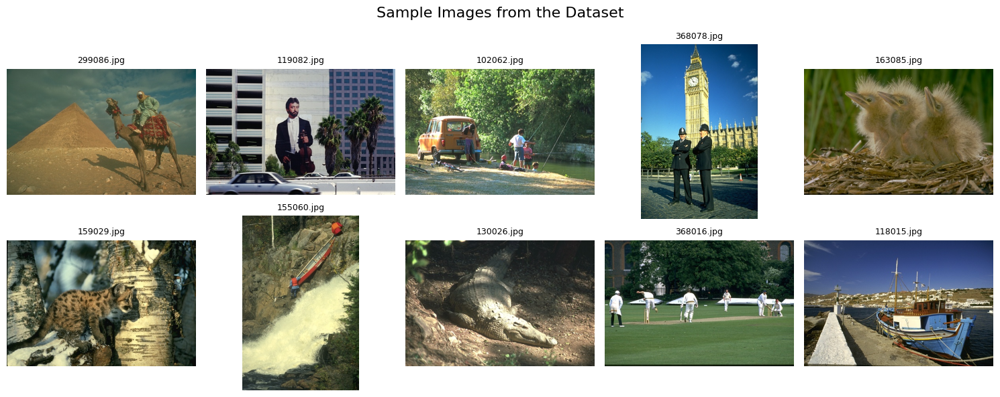

In [7]:
sample_images = random.sample(all_image_files, min(10, len(all_image_files)))

# Display: 2 rows × 5 columns
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, image_path in zip(axes.flat, sample_images):
    image = Image.open(image_path).convert("RGB")
    ax.imshow(image)
    ax.set_title(os.path.basename(image_path), fontsize=9)
    ax.axis("off")

plt.suptitle("Sample Images from the Dataset", fontsize=16)
plt.tight_layout()
plt.show()

#Dataset Split (70/15/15)

In [8]:
train_files, temp_files = train_test_split(
    all_image_files,
    test_size=(VAL_RATIO + TEST_RATIO),
    random_state=SEED,
    shuffle=True
)

relative_test_ratio = TEST_RATIO / (VAL_RATIO + TEST_RATIO)

val_files, test_files = train_test_split(
    temp_files,
    test_size=relative_test_ratio,
    random_state=SEED,
    shuffle=True
)

print("Total images :", len(all_image_files))
print("Train images :", len(train_files))
print("Val images   :", len(val_files))
print("Test images  :", len(test_files))

assert len(train_files) > 0
assert len(val_files) > 0
assert len(test_files) > 0

Total images : 500
Train images : 350
Val images   : 75
Test images  : 75


#Save dataset split

In [9]:
split_records = []

for path in train_files:
    split_records.append({
        "image_path": path,
        "split": "train"
    })

for path in val_files:
    split_records.append({
        "image_path": path,
        "split": "validation"
    })

for path in test_files:
    split_records.append({
        "image_path": path,
        "split": "test"
    })

split_df = pd.DataFrame(split_records)

split_csv_path = os.path.join(CSV_DIR, "Dataset_Split.csv")
split_df.to_csv(split_csv_path, index=False)

print("Saved:", split_csv_path)

display(split_df.head())

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Results/CSV/Dataset_Split.csv


,image_path,split
0,/content/drive/MyDrive/Computer_Vision_Assignm...,train
1,/content/drive/MyDrive/Computer_Vision_Assignm...,train
2,/content/drive/MyDrive/Computer_Vision_Assignm...,train
3,/content/drive/MyDrive/Computer_Vision_Assignm...,train
4,/content/drive/MyDrive/Computer_Vision_Assignm...,train


#Image transformation

In [10]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

#Gaussian noise function

In [11]:
def add_gaussian_noise(clean_image, sigma, generator=None):
    """
    clean_image: Tensor in [0,1]
    sigma: standard deviation on 0-255 scale
    """

    sigma_normalized = sigma / 255.0

    if generator is None:
        noise = torch.randn_like(clean_image)
    else:
        noise = torch.randn(
            clean_image.shape,
            generator=generator,
            dtype=clean_image.dtype
        )

    noise = noise * sigma_normalized

    noisy_image = clean_image + noise
    noisy_image = torch.clamp(noisy_image, 0.0, 1.0)

    # Actual residual after clipping
    residual = noisy_image - clean_image

    return noisy_image, residual

#Denoising dataset

In [12]:
class ImageDenoisingDataset(Dataset):

    def __init__(
        self,
        image_files,
        transform,
        noise_levels=(15, 25, 50),
        fixed_sigma=None,
        deterministic_noise=False,
        seed=42
    ):
        self.image_files = image_files
        self.transform = transform
        self.noise_levels = list(noise_levels)
        self.fixed_sigma = fixed_sigma
        self.deterministic_noise = deterministic_noise
        self.seed = seed

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):

        image_path = self.image_files[idx]

        image = Image.open(image_path).convert("RGB")
        clean_image = self.transform(image)

        if self.fixed_sigma is None:
            sigma = random.choice(self.noise_levels)
        else:
            sigma = self.fixed_sigma

        generator = None

        if self.deterministic_noise:
            generator = torch.Generator()
            generator.manual_seed(
                self.seed + idx * 1000 + int(sigma)
            )

        noisy_image, residual = add_gaussian_noise(
            clean_image,
            sigma,
            generator
        )

        return {
            "clean": clean_image,
            "noisy": noisy_image,
            "residual": residual,
            "sigma": torch.tensor(float(sigma)),
            "path": image_path
        }

#Create train and validation datasets

In [13]:
train_dataset = ImageDenoisingDataset(
    image_files=train_files,
    transform=train_transform,
    noise_levels=NOISE_LEVELS,
    fixed_sigma=None,
    deterministic_noise=False,
    seed=SEED
)

val_dataset = ImageDenoisingDataset(
    image_files=val_files,
    transform=eval_transform,
    noise_levels=NOISE_LEVELS,
    fixed_sigma=25,
    deterministic_noise=True,
    seed=SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 22
Validation batches: 5


#Visualize clean/noisy images at three noise levels

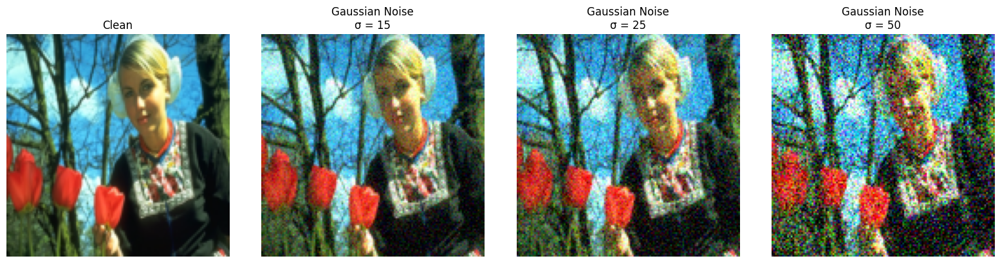

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Results/Figures/Gaussian_Noise_Levels.png


In [14]:
sample_path = test_files[0]

sample_image = Image.open(sample_path).convert("RGB")
sample_clean = eval_transform(sample_image)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(sample_clean.permute(1, 2, 0))
axes[0].set_title("Clean")
axes[0].axis("off")

for i, sigma in enumerate(NOISE_LEVELS):

    generator = torch.Generator()
    generator.manual_seed(SEED + sigma)

    noisy, _ = add_gaussian_noise(
        sample_clean,
        sigma,
        generator
    )

    axes[i + 1].imshow(noisy.permute(1, 2, 0))
    axes[i + 1].set_title(f"Gaussian Noise\nσ = {sigma}")
    axes[i + 1].axis("off")

plt.tight_layout()

noise_figure_path = os.path.join(
    FIGURE_DIR,
    "Gaussian_Noise_Levels.png"
)

plt.savefig(
    noise_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", noise_figure_path)

#Model 1: Denoising Autoencoder (DAE)

In [15]:
class DenoisingAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, 3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, 3, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                256, 128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 3, 3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

#Model 2: RED-Net

In [16]:
class REDNet(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.conv1 = nn.Conv2d(3, 64, 3, padding=1)
        self.conv2 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv4 = nn.Conv2d(64, 64, 3, padding=1)
        self.conv5 = nn.Conv2d(64, 64, 3, padding=1)

        # Decoder
        self.deconv1 = nn.ConvTranspose2d(
            64, 64, 3, padding=1
        )
        self.deconv2 = nn.ConvTranspose2d(
            64, 64, 3, padding=1
        )
        self.deconv3 = nn.ConvTranspose2d(
            64, 64, 3, padding=1
        )
        self.deconv4 = nn.ConvTranspose2d(
            64, 64, 3, padding=1
        )
        self.deconv5 = nn.ConvTranspose2d(
            64, 3, 3, padding=1
        )

    def forward(self, x):

        # Encoder
        e1 = F.relu(self.conv1(x))
        e2 = F.relu(self.conv2(e1))
        e3 = F.relu(self.conv3(e2))
        e4 = F.relu(self.conv4(e3))
        e5 = F.relu(self.conv5(e4))

        # Decoder with additive skip connections
        d1 = F.relu(self.deconv1(e5) + e4)
        d2 = F.relu(self.deconv2(d1) + e3)
        d3 = F.relu(self.deconv3(d2) + e2)
        d4 = F.relu(self.deconv4(d3) + e1)

        output = self.deconv5(d4)

        return torch.sigmoid(output)

#Model 3: U-Net

In [17]:
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

#Cell 16 — U-Net

In [18]:
class UNet(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(3, 32)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = DoubleConv(32, 64)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = DoubleConv(64, 128)
        self.pool3 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(128, 256)

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            256, 128,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(
            128, 64,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(
            64, 32,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(64, 32)

        self.final = nn.Conv2d(
            32,
            3,
            kernel_size=1
        )

    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool1(e1)
        )

        e3 = self.enc3(
            self.pool2(e2)
        )

        b = self.bottleneck(
            self.pool3(e3)
        )

        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)

        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)

        output = self.final(d1)

        return torch.sigmoid(output)

#Model 4: DnCNN

In [19]:
class DnCNN(nn.Module):

    def __init__(
        self,
        depth=17,
        features=64
    ):
        super().__init__()

        layers = []

        # First layer
        layers.append(
            nn.Conv2d(
                3,
                features,
                kernel_size=3,
                padding=1,
                bias=True
            )
        )

        layers.append(
            nn.ReLU(inplace=True)
        )

        # Middle layers
        for _ in range(depth - 2):

            layers.append(
                nn.Conv2d(
                    features,
                    features,
                    kernel_size=3,
                    padding=1,
                    bias=False
                )
            )

            layers.append(
                nn.BatchNorm2d(features)
            )

            layers.append(
                nn.ReLU(inplace=True)
            )

        # Final layer predicts residual noise
        layers.append(
            nn.Conv2d(
                features,
                3,
                kernel_size=3,
                padding=1,
                bias=True
            )
        )

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

#Proposed Model1 and Model2

To make the direct-vs-residual experiment scientifically fair, both proposed models will use the same backbone.

The only major difference is the learning target:



*  Model1: noisy → clean
*  Model2: noisy → residual noise




#Cell 18 — Proposed residual block

In [20]:
class ResidualBlock(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            channels,
            channels,
            3,
            padding=1
        )

        self.bn1 = nn.BatchNorm2d(channels)

        self.conv2 = nn.Conv2d(
            channels,
            channels,
            3,
            padding=1
        )

        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):

        identity = x

        out = F.relu(
            self.bn1(
                self.conv1(x)
            ),
            inplace=True
        )

        out = self.bn2(
            self.conv2(out)
        )

        out = out + identity

        return F.relu(
            out,
            inplace=True
        )

#Proposed denoising backbone

In [21]:
class ProposedDenoiser(nn.Module):

    def __init__(
        self,
        learning_type="direct",
        features=64,
        num_blocks=6
    ):
        super().__init__()

        assert learning_type in [
            "direct",
            "residual"
        ]

        self.learning_type = learning_type

        self.input_conv = nn.Sequential(
            nn.Conv2d(
                3,
                features,
                3,
                padding=1
            ),
            nn.ReLU(inplace=True)
        )

        blocks = []

        for _ in range(num_blocks):
            blocks.append(
                ResidualBlock(features)
            )

        self.residual_blocks = nn.Sequential(
            *blocks
        )

        # Multi-scale context
        self.dilated1 = nn.Conv2d(
            features,
            features,
            3,
            padding=1,
            dilation=1
        )

        self.dilated2 = nn.Conv2d(
            features,
            features,
            3,
            padding=2,
            dilation=2
        )

        self.dilated3 = nn.Conv2d(
            features,
            features,
            3,
            padding=4,
            dilation=4
        )

        self.fusion = nn.Sequential(
            nn.Conv2d(
                features * 3,
                features,
                1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                features,
                3,
                3,
                padding=1
            )
        )

    def forward(self, x):

        features = self.input_conv(x)

        features = self.residual_blocks(
            features
        )

        f1 = F.relu(
            self.dilated1(features),
            inplace=True
        )

        f2 = F.relu(
            self.dilated2(features),
            inplace=True
        )

        f3 = F.relu(
            self.dilated3(features),
            inplace=True
        )

        combined = torch.cat(
            [f1, f2, f3],
            dim=1
        )

        output = self.fusion(combined)

        if self.learning_type == "direct":
            output = torch.sigmoid(output)

        return output

#Instantiate All Six Models

In [22]:
models = {
    "DAE": DenoisingAutoencoder(),
    "RED-Net": REDNet(),
    "U-Net": UNet(),

    # Residual learning
    "DnCNN": DnCNN(
        depth=17,
        features=64
    ),

    # Proposed direct model
    "Model1": ProposedDenoiser(
        learning_type="direct",
        features=64,
        num_blocks=6
    ),

    # Same backbone, residual target
    "Model2": ProposedDenoiser(
        learning_type="residual",
        features=64,
        num_blocks=6
    )
}

learning_types = {
    "DAE": "Direct",
    "RED-Net": "Direct",
    "U-Net": "Direct",
    "DnCNN": "Residual",
    "Model1": "Direct",
    "Model2": "Residual"
}

targets = {
    "DAE": "Clean image",
    "RED-Net": "Clean image",
    "U-Net": "Clean image",
    "DnCNN": "Residual noise",
    "Model1": "Clean image",
    "Model2": "Residual noise"
}

for name, model in models.items():
    print(
        f"{name:10s} -> "
        f"{learning_types[name]:8s} -> "
        f"{targets[name]}"
    )

DAE        -> Direct   -> Clean image
RED-Net    -> Direct   -> Clean image
U-Net      -> Direct   -> Clean image
DnCNN      -> Residual -> Residual noise
Model1     -> Direct   -> Clean image
Model2     -> Residual -> Residual noise


#Verify Output Shapes

In [23]:
dummy_input = torch.randn(
    2,
    3,
    IMAGE_SIZE,
    IMAGE_SIZE
)

print("Input shape:", dummy_input.shape)
print()

for name, model in models.items():

    model.eval()

    with torch.no_grad():
        output = model(dummy_input)

    print(
        f"{name:10s}: "
        f"output shape = {tuple(output.shape)}"
    )

    assert output.shape == dummy_input.shape, (
        f"{name} output shape is incorrect."
    )

print("\nAll six model output shapes are correct.")

Input shape: torch.Size([2, 3, 128, 128])

DAE       : output shape = (2, 3, 128, 128)
RED-Net   : output shape = (2, 3, 128, 128)
U-Net     : output shape = (2, 3, 128, 128)
DnCNN     : output shape = (2, 3, 128, 128)
Model1    : output shape = (2, 3, 128, 128)
Model2    : output shape = (2, 3, 128, 128)

All six model output shapes are correct.


#Parameter Counts

In [24]:
parameter_records = []

for name, model in models.items():

    total_parameters = sum(
        p.numel()
        for p in model.parameters()
    )

    trainable_parameters = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    parameter_records.append({
        "Model": name,
        "Learning Type": learning_types[name],
        "Target": targets[name],
        "Total Parameters": total_parameters,
        "Trainable Parameters": trainable_parameters
    })

parameter_df = pd.DataFrame(
    parameter_records
)

parameter_df = parameter_df.sort_values(
    "Total Parameters"
).reset_index(drop=True)

display(parameter_df)

parameter_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Model_Parameter_Counts.csv"
    ),
    index=False
)

,Model,Learning Type,Target,Total Parameters,Trainable Parameters
0,RED-Net,Direct,Clean image,298947,298947
1,DnCNN,Residual,Residual noise,558403,558403
2,Model2,Residual,Residual noise,571331,571331
3,Model1,Direct,Clean image,571331,571331
4,DAE,Direct,Clean image,1397123,1397123
5,U-Net,Direct,Clean image,1925667,1925667


#Model Summaries

In [25]:
for name, model in models.items():

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    summary(
        model,
        input_size=(
            1,
            3,
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        depth=3,
        col_names=[
            "input_size",
            "output_size",
            "num_params"
        ]
    )


DAE

RED-Net

U-Net

DnCNN

Model1

Model2


#Draw Architectures

In [26]:
from torchview import draw_graph

for name, model in models.items():

    print("Drawing:", name)

    model_cpu = model.cpu()

    graph = draw_graph(
        model_cpu,
        input_size=(
            1,
            3,
            IMAGE_SIZE,
            IMAGE_SIZE
        ),
        expand_nested=True,
        graph_name=name.replace("-", "_"),
        depth=3
    )

    safe_name = name.replace("-", "_")

    output_path = os.path.join(
        ARCH_DIR,
        safe_name
    )

    graph.visual_graph.render(
        filename=output_path,
        format="png",
        cleanup=True
    )

    model.to(DEVICE)

print("\nArchitecture diagrams saved in:")
print(ARCH_DIR)

Drawing: DAE
Drawing: RED-Net
Drawing: U-Net
Drawing: DnCNN
Drawing: Model1
Drawing: Model2

Architecture diagrams saved in:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Results/Architectures


#Loss and helper (MSE)

In [27]:
criterion = nn.MSELoss()


def get_training_target(
    batch,
    learning_type
):

    if learning_type == "Direct":
        return batch["clean"]

    elif learning_type == "Residual":
        return batch["residual"]

    else:
        raise ValueError(
            f"Unknown learning type: {learning_type}"
        )

#Train one epoch

In [28]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    learning_type,
    device
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    for batch in loader:

        noisy = batch["noisy"].to(
            device,
            non_blocking=True
        )

        clean = batch["clean"].to(
            device,
            non_blocking=True
        )

        residual = batch["residual"].to(
            device,
            non_blocking=True
        )

        if learning_type == "Direct":
            target = clean
        else:
            target = residual

        optimizer.zero_grad(
            set_to_none=True
        )

        output = model(noisy)

        loss = criterion(
            output,
            target
        )

        loss.backward()

        optimizer.step()

        batch_size = noisy.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

    epoch_loss = (
        running_loss /
        total_samples
    )

    return epoch_loss

#Validation

In [29]:
def validate_model(
    model,
    loader,
    learning_type,
    device
):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    with torch.no_grad():

        for batch in loader:

            noisy = batch["noisy"].to(
                device,
                non_blocking=True
            )

            clean = batch["clean"].to(
                device,
                non_blocking=True
            )

            residual = batch["residual"].to(
                device,
                non_blocking=True
            )

            if learning_type == "Direct":
                target = clean
            else:
                target = residual

            output = model(noisy)

            loss = criterion(
                output,
                target
            )

            batch_size = noisy.size(0)

            running_loss += (
                loss.item() * batch_size
            )

            total_samples += batch_size

    validation_loss = (
        running_loss /
        total_samples
    )

    return validation_loss

#General training function

In [30]:
def train_model(
    model_name,
    model,
    train_loader,
    val_loader,
    epochs=20
):

    learning_type = learning_types[
        model_name
    ]

    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3
    )

    best_val_loss = float("inf")

    history = []

    model_start_time = time.time()

    for epoch in range(
        1,
        epochs + 1
    ):

        epoch_start = time.time()

        train_loss = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            learning_type=learning_type,
            device=DEVICE
        )

        val_loss = validate_model(
            model=model,
            loader=val_loader,
            learning_type=learning_type,
            device=DEVICE
        )

        scheduler.step(
            val_loss
        )

        epoch_time = (
            time.time() -
            epoch_start
        )

        current_lr = (
            optimizer.param_groups[0]["lr"]
        )

        history.append({
            "Model": model_name,
            "Epoch": epoch,
            "Train Loss": train_loss,
            "Validation Loss": val_loss,
            "Learning Rate": current_lr,
            "Epoch Time (s)": epoch_time
        })

        print(
            f"{model_name:10s} | "
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train: {train_loss:.6f} | "
            f"Val: {val_loss:.6f} | "
            f"LR: {current_lr:.2e} | "
            f"Time: {epoch_time:.2f}s"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            checkpoint = {
                "model_name": model_name,
                "learning_type": learning_type,
                "epoch": epoch,
                "best_val_loss": best_val_loss,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict()
            }

            checkpoint_path = os.path.join(
                MODEL_DIR,
                f"{model_name.replace('-', '_')}_Best.pth"
            )

            torch.save(
                checkpoint,
                checkpoint_path
            )

    total_training_time = (
        time.time() -
        model_start_time
    )

    history_df = pd.DataFrame(
        history
    )

    history_path = os.path.join(
        CSV_DIR,
        f"{model_name.replace('-', '_')}_Training_History.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    # Reload best checkpoint
    checkpoint_path = os.path.join(
        MODEL_DIR,
        f"{model_name.replace('-', '_')}_Best.pth"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    return (
        model,
        history_df,
        total_training_time,
        best_val_loss
    )

#Train All Six Models

In [31]:
trained_models = {}
training_histories = {}
training_summary = []

for model_name, model in models.items():

    print("\n")
    print("=" * 90)
    print("TRAINING:", model_name)
    print(
        "Learning type:",
        learning_types[model_name]
    )
    print(
        "Target:",
        targets[model_name]
    )
    print("=" * 90)

    trained_model, history_df, training_time, best_val_loss = train_model(
        model_name=model_name,
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        epochs=EPOCHS
    )

    trained_models[
        model_name
    ] = trained_model

    training_histories[
        model_name
    ] = history_df

    training_summary.append({
        "Model": model_name,
        "Learning Type": learning_types[model_name],
        "Target": targets[model_name],
        "Epochs": EPOCHS,
        "Best Validation Loss": best_val_loss,
        "Training Time (s)": training_time,
        "Training Time (min)": training_time / 60
    })

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

training_summary_df = pd.DataFrame(
    training_summary
)

training_summary_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Training_Time_Summary.csv"
    ),
    index=False
)

display(training_summary_df)



TRAINING: DAE
Learning type: Direct
Target: Clean image
DAE        | Epoch 01/20 | Train: 0.044058 | Val: 0.029498 | LR: 1.00e-03 | Time: 3.30s
DAE        | Epoch 02/20 | Train: 0.028629 | Val: 0.017145 | LR: 1.00e-03 | Time: 3.41s
DAE        | Epoch 03/20 | Train: 0.016672 | Val: 0.014316 | LR: 1.00e-03 | Time: 4.00s
DAE        | Epoch 04/20 | Train: 0.014214 | Val: 0.012899 | LR: 1.00e-03 | Time: 2.88s
DAE        | Epoch 05/20 | Train: 0.012676 | Val: 0.011032 | LR: 1.00e-03 | Time: 2.76s
DAE        | Epoch 06/20 | Train: 0.011802 | Val: 0.011301 | LR: 1.00e-03 | Time: 2.84s
DAE        | Epoch 07/20 | Train: 0.011474 | Val: 0.010554 | LR: 1.00e-03 | Time: 3.14s
DAE        | Epoch 08/20 | Train: 0.010971 | Val: 0.009995 | LR: 1.00e-03 | Time: 4.00s
DAE        | Epoch 09/20 | Train: 0.017023 | Val: 0.012989 | LR: 1.00e-03 | Time: 2.98s
DAE        | Epoch 10/20 | Train: 0.013171 | Val: 0.011222 | LR: 1.00e-03 | Time: 2.79s
DAE        | Epoch 11/20 | Train: 0.011409 | Val: 0.010369 | L

,Model,Learning Type,Target,Epochs,Best Validation Loss,Training Time (s),Training Time (min)
0,DAE,Direct,Clean image,20,0.004532,67.437384,1.123956
1,RED-Net,Direct,Clean image,20,0.001453,78.479066,1.307984
2,U-Net,Direct,Clean image,20,0.001884,62.201921,1.036699
3,DnCNN,Residual,Residual noise,20,0.006544,146.117684,2.435295
4,Model1,Direct,Clean image,20,0.001795,163.312855,2.721881
5,Model2,Residual,Residual noise,20,0.001606,163.875268,2.731254


#Training Curves

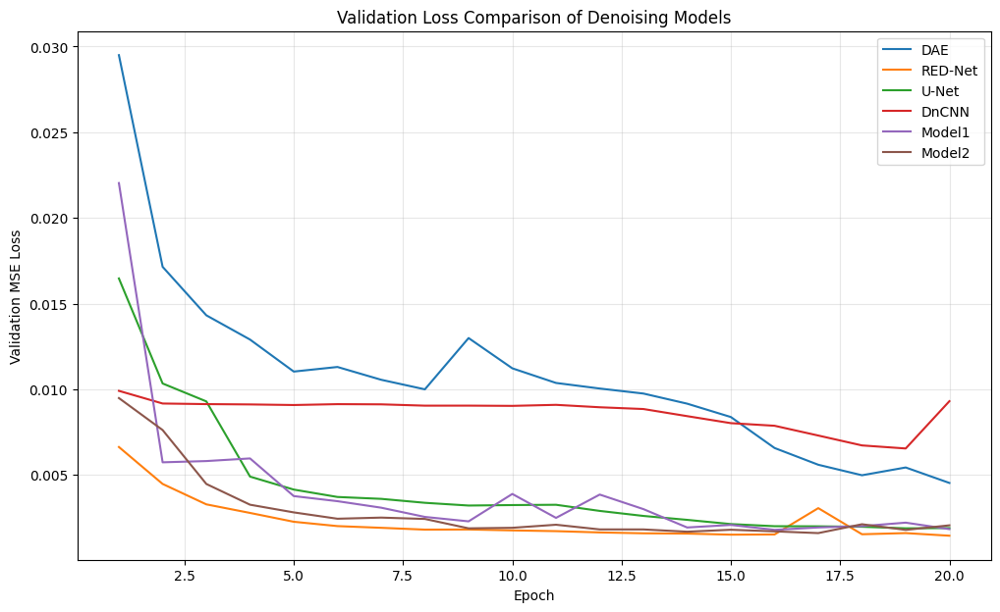

In [32]:
plt.figure(
    figsize=(12, 7)
)

for model_name, history_df in training_histories.items():

    plt.plot(
        history_df["Epoch"],
        history_df["Validation Loss"],
        label=model_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation MSE Loss")
plt.title(
    "Validation Loss Comparison of Denoising Models"
)
plt.legend()
plt.grid(alpha=0.3)

curve_path = os.path.join(
    FIGURE_DIR,
    "Validation_Loss_Comparison.png"
)

plt.savefig(
    curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Individual train/validation learning curves

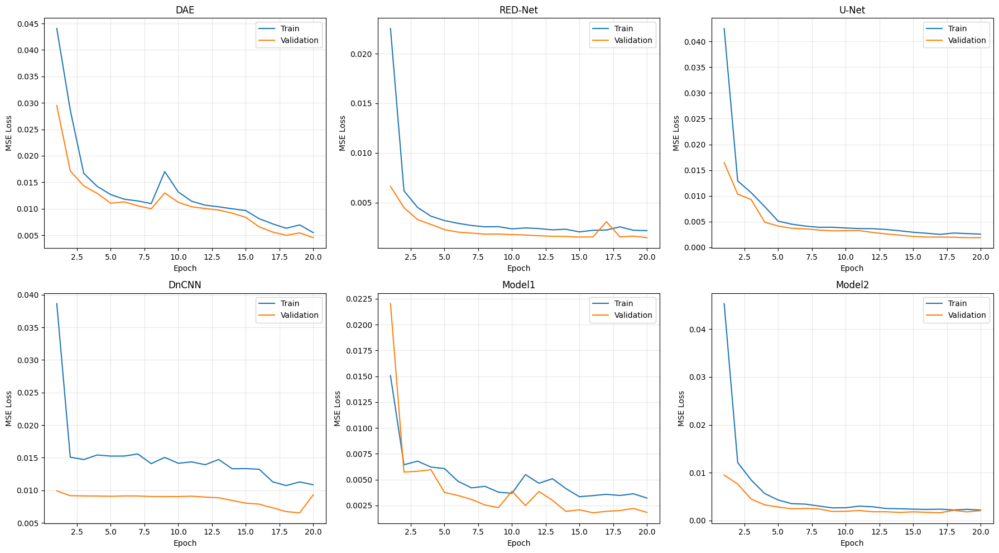

In [33]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 10)
)

axes = axes.flatten()

for ax, model_name in zip(
    axes,
    trained_models.keys()
):

    history_df = training_histories[
        model_name
    ]

    ax.plot(
        history_df["Epoch"],
        history_df["Train Loss"],
        label="Train"
    )

    ax.plot(
        history_df["Epoch"],
        history_df["Validation Loss"],
        label="Validation"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

individual_curve_path = os.path.join(
    FIGURE_DIR,
    "All_Model_Learning_Curves.png"
)

plt.savefig(
    individual_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#MSE, PSNR and SSIM

In [34]:
def calculate_mse(
    clean,
    denoised
):
    return np.mean(
        (clean - denoised) ** 2
    )


def calculate_psnr(
    clean,
    denoised
):

    mse = calculate_mse(
        clean,
        denoised
    )

    if mse == 0:
        return float("inf")

    return 10 * np.log10(
        1.0 / mse
    )


def calculate_ssim(
    clean,
    denoised
):

    return skimage_ssim(
        clean,
        denoised,
        channel_axis=-1,
        data_range=1.0
    )

#Reconstruct Clean Image Correctly

In [35]:
def obtain_denoised_image(
    model,
    noisy,
    learning_type
):

    prediction = model(noisy)

    if learning_type == "Direct":

        denoised = prediction

    elif learning_type == "Residual":

        predicted_noise = prediction

        denoised = (
            noisy -
            predicted_noise
        )

    else:
        raise ValueError(
            "Unknown learning type."
        )

    denoised = torch.clamp(
        denoised,
        0.0,
        1.0
    )

    return denoised

#Test Dataset at Different Sigma Levels

In [36]:
test_loaders = {}

for sigma in NOISE_LEVELS:

    test_dataset_sigma = ImageDenoisingDataset(
        image_files=test_files,
        transform=eval_transform,
        fixed_sigma=sigma,
        deterministic_noise=True,
        seed=SEED
    )

    test_loader_sigma = DataLoader(
        test_dataset_sigma,
        batch_size=1,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True
    )

    test_loaders[
        sigma
    ] = test_loader_sigma

    print(
        f"σ={sigma}: "
        f"{len(test_dataset_sigma)} test images"
    )

σ=15: 75 test images
σ=25: 75 test images
σ=50: 75 test images


#Evaluate One Model

In [37]:
def evaluate_model(
    model_name,
    model,
    loader,
    sigma
):

    learning_type = learning_types[
        model_name
    ]

    model.eval()
    model.to(DEVICE)

    mse_scores = []
    psnr_scores = []
    ssim_scores = []
    inference_times = []

    with torch.no_grad():

        for batch in loader:

            clean = batch["clean"].to(
                DEVICE
            )

            noisy = batch["noisy"].to(
                DEVICE
            )

            # Warm synchronization for accurate GPU timing
            if torch.cuda.is_available():
                torch.cuda.synchronize()

            start_time = time.perf_counter()

            denoised = obtain_denoised_image(
                model,
                noisy,
                learning_type
            )

            if torch.cuda.is_available():
                torch.cuda.synchronize()

            inference_time = (
                time.perf_counter() -
                start_time
            )

            inference_times.append(
                inference_time
            )

            clean_np = (
                clean[0]
                .detach()
                .cpu()
                .permute(1, 2, 0)
                .numpy()
            )

            denoised_np = (
                denoised[0]
                .detach()
                .cpu()
                .permute(1, 2, 0)
                .numpy()
            )

            clean_np = np.clip(
                clean_np,
                0,
                1
            )

            denoised_np = np.clip(
                denoised_np,
                0,
                1
            )

            mse_scores.append(
                calculate_mse(
                    clean_np,
                    denoised_np
                )
            )

            psnr_scores.append(
                calculate_psnr(
                    clean_np,
                    denoised_np
                )
            )

            ssim_scores.append(
                calculate_ssim(
                    clean_np,
                    denoised_np
                )
            )

    return {
        "Model": model_name,
        "Learning Type": learning_type,
        "Target": targets[model_name],
        "Noise Sigma": sigma,

        "MSE": np.mean(mse_scores),
        "PSNR": np.mean(psnr_scores),
        "SSIM": np.mean(ssim_scores),

        "Average Inference Time (s)": np.mean(
            inference_times
        ),

        "Total Inference Time (s)": np.sum(
            inference_times
        )
    }

#Evaluate All Six Models at $\sigma=15,25,50$

In [38]:
evaluation_results = []

for sigma in NOISE_LEVELS:

    print("\n")
    print("=" * 80)
    print(
        f"EVALUATION FOR GAUSSIAN NOISE σ = {sigma}"
    )
    print("=" * 80)

    loader = test_loaders[
        sigma
    ]

    for model_name, model in trained_models.items():

        result = evaluate_model(
            model_name,
            model,
            loader,
            sigma
        )

        evaluation_results.append(
            result
        )

        print(
            f"{model_name:10s} | "
            f"MSE: {result['MSE']:.6f} | "
            f"PSNR: {result['PSNR']:.3f} dB | "
            f"SSIM: {result['SSIM']:.4f}"
        )

evaluation_df = pd.DataFrame(
    evaluation_results
)

evaluation_csv = os.path.join(
    CSV_DIR,
    "All_Model_All_Noise_Evaluation.csv"
)

evaluation_df.to_csv(
    evaluation_csv,
    index=False
)

display(evaluation_df)



EVALUATION FOR GAUSSIAN NOISE σ = 15
DAE        | MSE: 0.004531 | PSNR: 23.968 dB | SSIM: 0.7291
RED-Net    | MSE: 0.001097 | PSNR: 29.956 dB | SSIM: 0.8794
U-Net      | MSE: 0.001583 | PSNR: 28.405 dB | SSIM: 0.8627
DnCNN      | MSE: 0.002572 | PSNR: 25.904 dB | SSIM: 0.6795
Model1     | MSE: 0.001507 | PSNR: 28.617 dB | SSIM: 0.8714
Model2     | MSE: 0.000958 | PSNR: 30.345 dB | SSIM: 0.8640


EVALUATION FOR GAUSSIAN NOISE σ = 25
DAE        | MSE: 0.004649 | PSNR: 23.840 dB | SSIM: 0.7131
RED-Net    | MSE: 0.001534 | PSNR: 28.331 dB | SSIM: 0.8170
U-Net      | MSE: 0.001981 | PSNR: 27.277 dB | SSIM: 0.8046
DnCNN      | MSE: 0.006399 | PSNR: 21.949 dB | SSIM: 0.5200
Model1     | MSE: 0.001867 | PSNR: 27.577 dB | SSIM: 0.8285
Model2     | MSE: 0.001658 | PSNR: 27.916 dB | SSIM: 0.7831


EVALUATION FOR GAUSSIAN NOISE σ = 50
DAE        | MSE: 0.005321 | PSNR: 23.152 dB | SSIM: 0.6525
RED-Net    | MSE: 0.003450 | PSNR: 24.681 dB | SSIM: 0.6534
U-Net      | MSE: 0.003695 | PSNR: 24.408 d

,Model,Learning Type,Target,Noise Sigma,MSE,PSNR,SSIM,Average Inference Time (s),Total Inference Time (s)
0,DAE,Direct,Clean image,15,0.004531,23.968290,0.729147,0.004371,0.327803
1,RED-Net,Direct,Clean image,15,0.001097,29.955658,0.879409,0.004498,0.337324
2,U-Net,Direct,Clean image,15,0.001583,28.404747,0.862731,0.004812,0.360913
3,DnCNN,Residual,Residual noise,15,0.002572,25.904259,0.679538,0.008678,0.650815
4,Model1,Direct,Clean image,15,0.001507,28.616949,0.871429,0.009962,0.747181
5,Model2,Residual,Residual noise,15,0.000958,30.344910,0.864030,0.007524,0.564273
6,DAE,Direct,Clean image,25,0.004649,23.839712,0.713132,0.003424,0.256830
7,RED-Net,Direct,Clean image,25,0.001534,28.330860,0.817047,0.003382,0.253646
8,U-Net,Direct,Clean image,25,0.001981,27.276722,0.804561,0.004221,0.316599
9,DnCNN,Residual,Residual noise,25,0.006399,21.949390,0.519994,0.006384,0.478826


#Main model comparison table

In [39]:
experiment1_df = (
    evaluation_df[
        evaluation_df["Noise Sigma"] == 25
    ]
    .copy()
    .sort_values(
        "PSNR",
        ascending=False
    )
    .reset_index(drop=True)
)

main_columns = [
    "Model",
    "Learning Type",
    "Target",
    "MSE",
    "PSNR",
    "SSIM"
]

display(
    experiment1_df[
        main_columns
    ]
)

experiment1_df[
    main_columns
].to_csv(
    os.path.join(
        CSV_DIR,
        "Experiment1_Model_Comparison.csv"
    ),
    index=False
)

,Model,Learning Type,Target,MSE,PSNR,SSIM
0,RED-Net,Direct,Clean image,0.001534,28.330860,0.817047
1,Model2,Residual,Residual noise,0.001658,27.916348,0.783101
2,Model1,Direct,Clean image,0.001867,27.577467,0.828502
3,U-Net,Direct,Clean image,0.001981,27.276722,0.804561
4,DAE,Direct,Clean image,0.004649,23.839712,0.713132
5,DnCNN,Residual,Residual noise,0.006399,21.949390,0.519994


#Determine best models automatically

In [40]:
best_mse_row = experiment1_df.loc[
    experiment1_df["MSE"].idxmin()
]

best_psnr_row = experiment1_df.loc[
    experiment1_df["PSNR"].idxmax()
]

best_ssim_row = experiment1_df.loc[
    experiment1_df["SSIM"].idxmax()
]

print(
    "Best MSE:",
    best_mse_row["Model"],
    "=",
    best_mse_row["MSE"]
)

print(
    "Best PSNR:",
    best_psnr_row["Model"],
    "=",
    best_psnr_row["PSNR"],
    "dB"
)

print(
    "Best SSIM:",
    best_ssim_row["Model"],
    "=",
    best_ssim_row["SSIM"]
)

Best MSE: RED-Net = 0.0015339409
Best PSNR: RED-Net = 28.33086 dB
Best SSIM: Model1 = 0.8285017


#Group comparison

In [41]:
experiment2_group_df = (
    experiment1_df
    .groupby("Learning Type")[
        ["MSE", "PSNR", "SSIM"]
    ]
    .mean()
    .reset_index()
)

display(
    experiment2_group_df
)

experiment2_group_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Experiment2_Direct_vs_Residual_Group.csv"
    ),
    index=False
)

,Learning Type,MSE,PSNR,SSIM
0,Direct,0.002508,26.756191,0.790810
1,Residual,0.004028,24.932869,0.651548


#Controlled Model1 vs Model2 comparison

In [42]:
model1_model2_df = experiment1_df[
    experiment1_df["Model"].isin(
        ["Model1", "Model2"]
    )
][
    [
        "Model",
        "Learning Type",
        "Target",
        "MSE",
        "PSNR",
        "SSIM"
    ]
].copy()

display(
    model1_model2_df
)

model1_model2_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Experiment2_Model1_vs_Model2.csv"
    ),
    index=False
)

,Model,Learning Type,Target,MSE,PSNR,SSIM
1,Model2,Residual,Residual noise,0.001658,27.916348,0.783101
2,Model1,Direct,Clean image,0.001867,27.577467,0.828502


#Complete noise-level comparison

In [43]:
experiment3_df = evaluation_df[
    [
        "Model",
        "Learning Type",
        "Noise Sigma",
        "MSE",
        "PSNR",
        "SSIM"
    ]
].copy()

display(
    experiment3_df
)

experiment3_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Experiment3_Noise_Level_Comparison.csv"
    ),
    index=False
)

,Model,Learning Type,Noise Sigma,MSE,PSNR,SSIM
0,DAE,Direct,15,0.004531,23.968290,0.729147
1,RED-Net,Direct,15,0.001097,29.955658,0.879409
2,U-Net,Direct,15,0.001583,28.404747,0.862731
3,DnCNN,Residual,15,0.002572,25.904259,0.679538
4,Model1,Direct,15,0.001507,28.616949,0.871429
5,Model2,Residual,15,0.000958,30.344910,0.864030
6,DAE,Direct,25,0.004649,23.839712,0.713132
7,RED-Net,Direct,25,0.001534,28.330860,0.817047
8,U-Net,Direct,25,0.001981,27.276722,0.804561
9,DnCNN,Residual,25,0.006399,21.949390,0.519994


#PSNR vs noise level graph

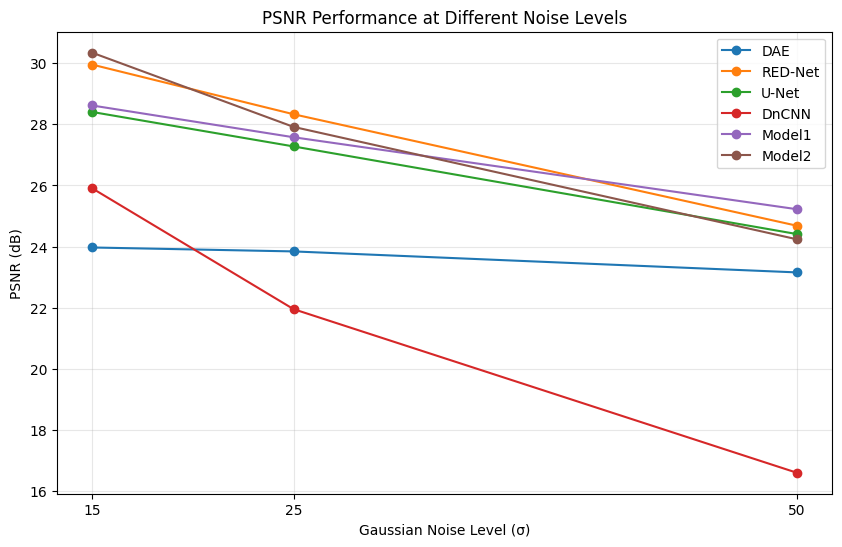

In [44]:
plt.figure(
    figsize=(10, 6)
)

for model_name in trained_models.keys():

    model_results = experiment3_df[
        experiment3_df["Model"] == model_name
    ].sort_values(
        "Noise Sigma"
    )

    plt.plot(
        model_results["Noise Sigma"],
        model_results["PSNR"],
        marker="o",
        label=model_name
    )

plt.xlabel("Gaussian Noise Level (σ)")
plt.ylabel("PSNR (dB)")
plt.title(
    "PSNR Performance at Different Noise Levels"
)
plt.xticks(NOISE_LEVELS)
plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "PSNR_vs_Noise_Level.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#SSIM vs noise level

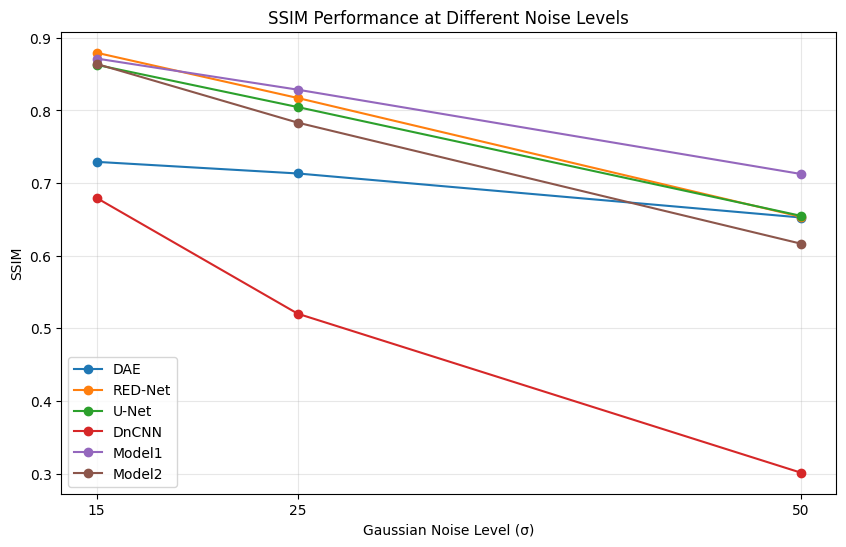

In [45]:
plt.figure(
    figsize=(10, 6)
)

for model_name in trained_models.keys():

    model_results = experiment3_df[
        experiment3_df["Model"] == model_name
    ].sort_values(
        "Noise Sigma"
    )

    plt.plot(
        model_results["Noise Sigma"],
        model_results["SSIM"],
        marker="o",
        label=model_name
    )

plt.xlabel("Gaussian Noise Level (σ)")
plt.ylabel("SSIM")
plt.title(
    "SSIM Performance at Different Noise Levels"
)
plt.xticks(NOISE_LEVELS)
plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "SSIM_vs_Noise_Level.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#MSE vs noise level

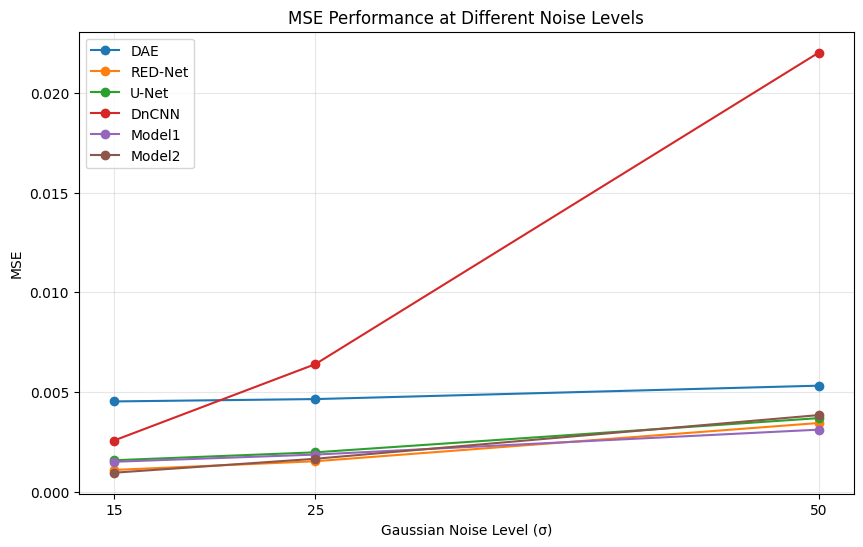

In [46]:
plt.figure(
    figsize=(10, 6)
)

for model_name in trained_models.keys():

    model_results = experiment3_df[
        experiment3_df["Model"] == model_name
    ].sort_values(
        "Noise Sigma"
    )

    plt.plot(
        model_results["Noise Sigma"],
        model_results["MSE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Gaussian Noise Level (σ)")
plt.ylabel("MSE")
plt.title(
    "MSE Performance at Different Noise Levels"
)
plt.xticks(NOISE_LEVELS)
plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "MSE_vs_Noise_Level.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Helper to generate all model outputs

In [47]:
def denoise_with_all_models(
    clean_tensor,
    sigma
):

    generator = torch.Generator()
    generator.manual_seed(
        SEED + sigma
    )

    noisy_tensor, _ = add_gaussian_noise(
        clean_tensor,
        sigma,
        generator
    )

    noisy_batch = (
        noisy_tensor
        .unsqueeze(0)
        .to(DEVICE)
    )

    outputs = {}

    for model_name, model in trained_models.items():

        model.eval()

        with torch.no_grad():

            denoised = obtain_denoised_image(
                model,
                noisy_batch,
                learning_types[model_name]
            )

        outputs[
            model_name
        ] = (
            denoised[0]
            .cpu()
        )

    return (
        noisy_tensor,
        outputs
    )

#Visual comparison for several images
##sigma = 15

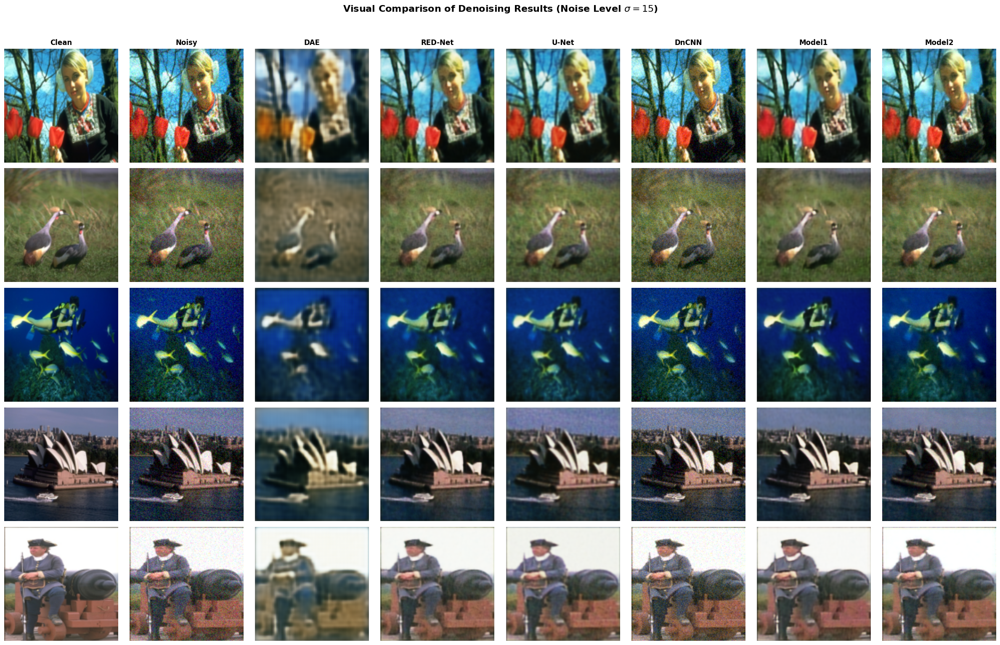

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Results/Figures/Experiment4_Visual_Comparison15.png


In [48]:
NUM_VISUAL_IMAGES = min(
    5,
    len(test_files)
)

VISUAL_SIGMA = 15

selected_visual_files = test_files[
    :NUM_VISUAL_IMAGES
]

column_names = [
    "Clean",
    "Noisy",
    "DAE",
    "RED-Net",
    "U-Net",
    "DnCNN",
    "Model1",
    "Model2"
]

fig, axes = plt.subplots(
    NUM_VISUAL_IMAGES,
    8,
    figsize=(24, 3 * NUM_VISUAL_IMAGES)
)

if NUM_VISUAL_IMAGES == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_idx, image_path in enumerate(
    selected_visual_files
):

    image = Image.open(
        image_path
    ).convert("RGB")

    clean = eval_transform(
        image
    )

    noisy, outputs = denoise_with_all_models(
        clean,
        VISUAL_SIGMA
    )

    images_to_show = [
        clean,
        noisy,
        outputs["DAE"],
        outputs["RED-Net"],
        outputs["U-Net"],
        outputs["DnCNN"],
        outputs["Model1"],
        outputs["Model2"]
    ]

    for col_idx, (
        tensor_image,
        title
    ) in enumerate(
        zip(
            images_to_show,
            column_names
        )
    ):

        axes[
            row_idx,
            col_idx
        ].imshow(
            tensor_image
            .permute(1, 2, 0)
            .numpy()
            .clip(0, 1)
        )

        axes[
            row_idx,
            col_idx
        ].axis("off")

        if row_idx == 0:

            axes[
                row_idx,
                col_idx
            ].set_title(
                title,
                fontsize=12,
                fontweight="bold"
            )
fig.suptitle(
    f"Visual Comparison of Denoising Results (Noise Level $\\sigma = {VISUAL_SIGMA}$)",
    fontsize=16,
    fontweight="bold",
    y=1.02)

plt.tight_layout()

visual_comparison_path = os.path.join(
    FIGURE_DIR,
    "Experiment4_Visual_Comparison15.png"
)

plt.savefig(
    visual_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    visual_comparison_path
)

#Visual comparison for several images
##sigma = 25

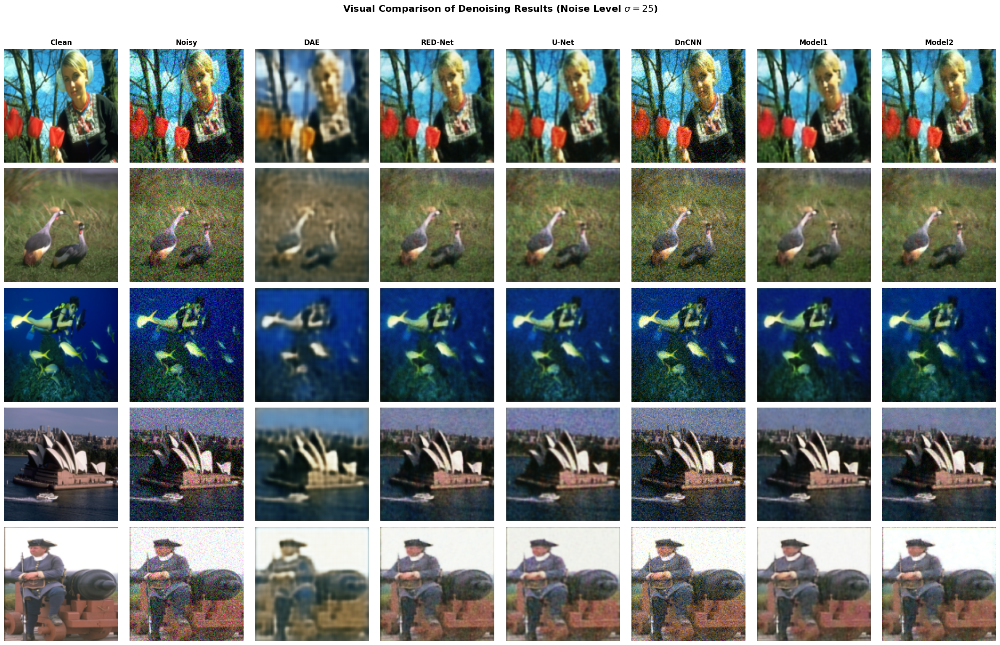

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Results/Figures/Experiment4_Visual_Comparison25.png


In [49]:
NUM_VISUAL_IMAGES = min(
    5,
    len(test_files)
)

VISUAL_SIGMA = 25

selected_visual_files = test_files[
    :NUM_VISUAL_IMAGES
]

column_names = [
    "Clean",
    "Noisy",
    "DAE",
    "RED-Net",
    "U-Net",
    "DnCNN",
    "Model1",
    "Model2"
]

fig, axes = plt.subplots(
    NUM_VISUAL_IMAGES,
    8,
    figsize=(24, 3 * NUM_VISUAL_IMAGES)
)

if NUM_VISUAL_IMAGES == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_idx, image_path in enumerate(
    selected_visual_files
):

    image = Image.open(
        image_path
    ).convert("RGB")

    clean = eval_transform(
        image
    )

    noisy, outputs = denoise_with_all_models(
        clean,
        VISUAL_SIGMA
    )

    images_to_show = [
        clean,
        noisy,
        outputs["DAE"],
        outputs["RED-Net"],
        outputs["U-Net"],
        outputs["DnCNN"],
        outputs["Model1"],
        outputs["Model2"]
    ]

    for col_idx, (
        tensor_image,
        title
    ) in enumerate(
        zip(
            images_to_show,
            column_names
        )
    ):

        axes[
            row_idx,
            col_idx
        ].imshow(
            tensor_image
            .permute(1, 2, 0)
            .numpy()
            .clip(0, 1)
        )

        axes[
            row_idx,
            col_idx
        ].axis("off")

        if row_idx == 0:

            axes[
                row_idx,
                col_idx
            ].set_title(
                title,
                fontsize=12,
                fontweight="bold"
            )

fig.suptitle(
    f"Visual Comparison of Denoising Results (Noise Level $\\sigma = {VISUAL_SIGMA}$)",
    fontsize=16,
    fontweight="bold",
    y=1.02)

plt.tight_layout()

visual_comparison_path = os.path.join(
    FIGURE_DIR,
    "Experiment4_Visual_Comparison25.png"
)

plt.savefig(
    visual_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    visual_comparison_path
)

#Visual comparison for several images
##sigma = 50

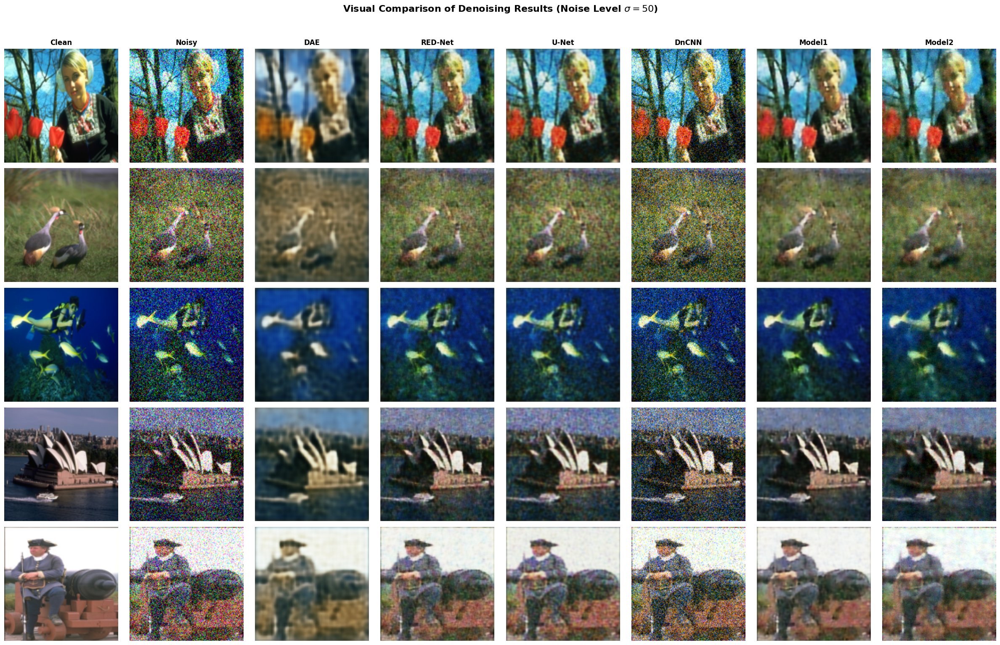

Saved: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising/Results/Figures/Experiment4_Visual_Comparison50.png


In [50]:
NUM_VISUAL_IMAGES = min(
    5,
    len(test_files)
)

VISUAL_SIGMA = 50

selected_visual_files = test_files[
    :NUM_VISUAL_IMAGES
]

column_names = [
    "Clean",
    "Noisy",
    "DAE",
    "RED-Net",
    "U-Net",
    "DnCNN",
    "Model1",
    "Model2"
]

fig, axes = plt.subplots(
    NUM_VISUAL_IMAGES,
    8,
    figsize=(24, 3 * NUM_VISUAL_IMAGES)
)

if NUM_VISUAL_IMAGES == 1:
    axes = np.expand_dims(
        axes,
        axis=0
    )

for row_idx, image_path in enumerate(
    selected_visual_files
):

    image = Image.open(
        image_path
    ).convert("RGB")

    clean = eval_transform(
        image
    )

    noisy, outputs = denoise_with_all_models(
        clean,
        VISUAL_SIGMA
    )

    images_to_show = [
        clean,
        noisy,
        outputs["DAE"],
        outputs["RED-Net"],
        outputs["U-Net"],
        outputs["DnCNN"],
        outputs["Model1"],
        outputs["Model2"]
    ]

    for col_idx, (
        tensor_image,
        title
    ) in enumerate(
        zip(
            images_to_show,
            column_names
        )
    ):

        axes[
            row_idx,
            col_idx
        ].imshow(
            tensor_image
            .permute(1, 2, 0)
            .numpy()
            .clip(0, 1)
        )

        axes[
            row_idx,
            col_idx
        ].axis("off")

        if row_idx == 0:

            axes[
                row_idx,
                col_idx
            ].set_title(
                title,
                fontsize=12,
                fontweight="bold"
            )

fig.suptitle(
    f"Visual Comparison of Denoising Results (Noise Level $\\sigma = {VISUAL_SIGMA}$)",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

visual_comparison_path = os.path.join(
    FIGURE_DIR,
    "Experiment4_Visual_Comparison50.png"
)

plt.savefig(
    visual_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    visual_comparison_path
)

#Save Individual Denoised Outputs

In [51]:
SAVE_SIGMA = 25

for model_name in trained_models.keys():

    model_output_dir = os.path.join(
        OUTPUT_DIR,
        model_name.replace("-", "_"),
        f"Sigma_{SAVE_SIGMA}"
    )

    os.makedirs(
        model_output_dir,
        exist_ok=True
    )

loader = test_loaders[
    SAVE_SIGMA
]

for idx, batch in enumerate(loader):

    noisy = batch["noisy"].to(
        DEVICE
    )

    for model_name, model in trained_models.items():

        model.eval()

        with torch.no_grad():

            denoised = obtain_denoised_image(
                model,
                noisy,
                learning_types[model_name]
            )

        output_path = os.path.join(
            OUTPUT_DIR,
            model_name.replace("-", "_"),
            f"Sigma_{SAVE_SIGMA}",
            f"test_{idx + 1:03d}.png"
        )

        save_image(
            denoised[0],
            output_path
        )

print(
    "Denoised images saved successfully."
)

Denoised images saved successfully.


#Merge parameters, training and inference time

In [52]:
# Average inference time at sigma = 25
inference_25_df = evaluation_df[
    evaluation_df["Noise Sigma"] == 25
][
    [
        "Model",
        "Average Inference Time (s)"
    ]
].copy()

computational_df = (
    parameter_df
    .merge(
        training_summary_df[
            [
                "Model",
                "Training Time (s)",
                "Training Time (min)"
            ]
        ],
        on="Model",
        how="left"
    )
    .merge(
        inference_25_df,
        on="Model",
        how="left"
    )
)

display(
    computational_df
)

computational_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Computational_Requirements.csv"
    ),
    index=False
)

,Model,Learning Type,Target,Total Parameters,Trainable Parameters,Training Time (s),Training Time (min),Average Inference Time (s)
0,RED-Net,Direct,Clean image,298947,298947,78.479066,1.307984,0.003382
1,DnCNN,Residual,Residual noise,558403,558403,146.117684,2.435295,0.006384
2,Model2,Residual,Residual noise,571331,571331,163.875268,2.731254,0.005886
3,Model1,Direct,Clean image,571331,571331,163.312855,2.721881,0.006156
4,DAE,Direct,Clean image,1397123,1397123,67.437384,1.123956,0.003424
5,U-Net,Direct,Clean image,1925667,1925667,62.201921,1.036699,0.004221


#Final Main Results Table

In [53]:
final_results_df = experiment1_df[
    [
        "Model",
        "Learning Type",
        "Target",
        "MSE",
        "PSNR",
        "SSIM"
    ]
].copy()

display(
    final_results_df.style.format({
        "MSE": "{:.6f}",
        "PSNR": "{:.3f}",
        "SSIM": "{:.4f}"
    })
)

final_results_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Final_Main_Results_Table.csv"
    ),
    index=False
)

,Model,Learning Type,Target,MSE,PSNR,SSIM
0,RED-Net,Direct,Clean image,0.001534,28.331,0.8170
1,Model2,Residual,Residual noise,0.001658,27.916,0.7831
2,Model1,Direct,Clean image,0.001867,27.577,0.8285
3,U-Net,Direct,Clean image,0.001981,27.277,0.8046
4,DAE,Direct,Clean image,0.004649,23.840,0.7131
5,DnCNN,Residual,Residual noise,0.006399,21.949,0.5200


#Rank Models

In [54]:
ranking_df = final_results_df.copy()

ranking_df["MSE Rank"] = ranking_df[
    "MSE"
].rank(
    ascending=True,
    method="min"
)

ranking_df["PSNR Rank"] = ranking_df[
    "PSNR"
].rank(
    ascending=False,
    method="min"
)

ranking_df["SSIM Rank"] = ranking_df[
    "SSIM"
].rank(
    ascending=False,
    method="min"
)

ranking_df["Average Rank"] = ranking_df[
    [
        "MSE Rank",
        "PSNR Rank",
        "SSIM Rank"
    ]
].mean(axis=1)

ranking_df = ranking_df.sort_values(
    "Average Rank"
).reset_index(drop=True)

display(
    ranking_df
)

ranking_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Model_Ranking.csv"
    ),
    index=False
)

,Model,Learning Type,Target,MSE,PSNR,SSIM,MSE Rank,PSNR Rank,SSIM Rank,Average Rank
0,RED-Net,Direct,Clean image,0.001534,28.330860,0.817047,1.0,1.0,2.0,1.333333
1,Model1,Direct,Clean image,0.001867,27.577467,0.828502,3.0,3.0,1.0,2.333333
2,Model2,Residual,Residual noise,0.001658,27.916348,0.783101,2.0,2.0,4.0,2.666667
3,U-Net,Direct,Clean image,0.001981,27.276722,0.804561,4.0,4.0,3.0,3.666667
4,DAE,Direct,Clean image,0.004649,23.839712,0.713132,5.0,5.0,5.0,5.000000
5,DnCNN,Residual,Residual noise,0.006399,21.949390,0.519994,6.0,6.0,6.0,6.000000


#PSNR comparison

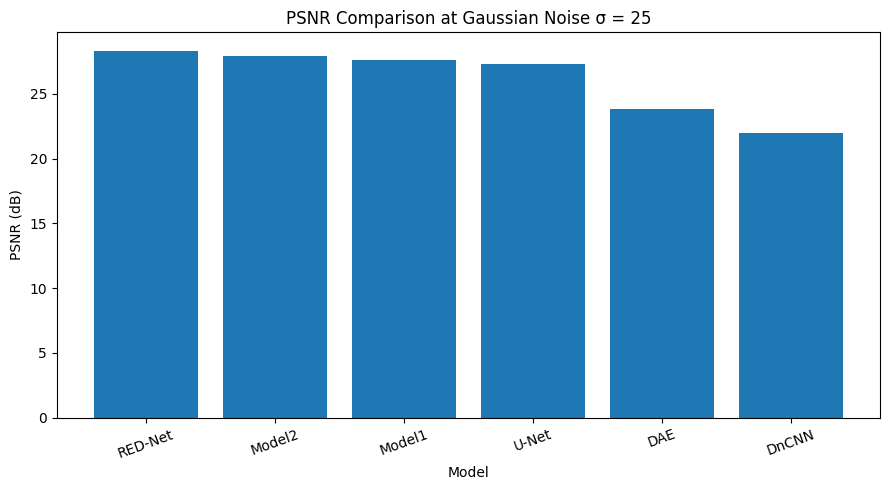

In [55]:
plot_df = final_results_df.sort_values(
    "PSNR",
    ascending=False
)

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    plot_df["Model"],
    plot_df["PSNR"]
)

plt.ylabel("PSNR (dB)")
plt.xlabel("Model")
plt.title(
    "PSNR Comparison at Gaussian Noise σ = 25"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Model_PSNR_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#SSIM comparison

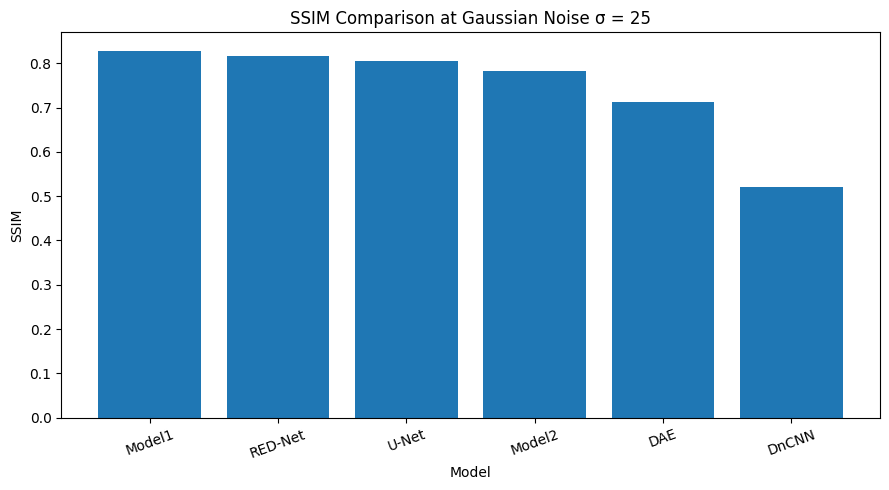

In [56]:
plot_df = final_results_df.sort_values(
    "SSIM",
    ascending=False
)

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    plot_df["Model"],
    plot_df["SSIM"]
)

plt.ylabel("SSIM")
plt.xlabel("Model")
plt.title(
    "SSIM Comparison at Gaussian Noise σ = 25"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Model_SSIM_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#MSE comparison

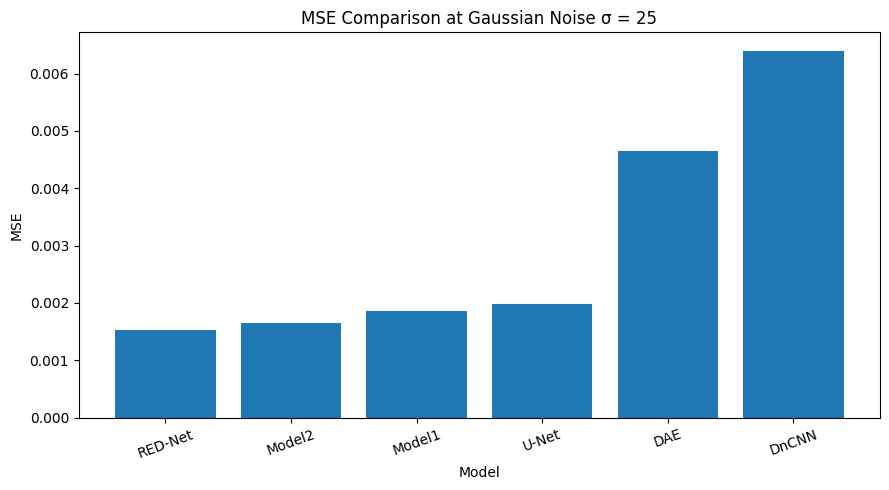

In [57]:
plot_df = final_results_df.sort_values(
    "MSE"
)

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    plot_df["Model"],
    plot_df["MSE"]
)

plt.ylabel("MSE")
plt.xlabel("Model")
plt.title(
    "MSE Comparison at Gaussian Noise σ = 25"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURE_DIR,
        "Model_MSE_Comparison.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Noisy Image Baseline

In [58]:
baseline_results = []

for sigma in NOISE_LEVELS:

    dataset = ImageDenoisingDataset(
        image_files=test_files,
        transform=eval_transform,
        fixed_sigma=sigma,
        deterministic_noise=True,
        seed=SEED
    )

    mse_values = []
    psnr_values = []
    ssim_values = []

    for idx in range(
        len(dataset)
    ):

        sample = dataset[idx]

        clean_np = (
            sample["clean"]
            .permute(1, 2, 0)
            .numpy()
        )

        noisy_np = (
            sample["noisy"]
            .permute(1, 2, 0)
            .numpy()
        )

        mse_values.append(
            calculate_mse(
                clean_np,
                noisy_np
            )
        )

        psnr_values.append(
            calculate_psnr(
                clean_np,
                noisy_np
            )
        )

        ssim_values.append(
            calculate_ssim(
                clean_np,
                noisy_np
            )
        )

    baseline_results.append({
        "Noise Sigma": sigma,
        "Noisy MSE": np.mean(mse_values),
        "Noisy PSNR": np.mean(psnr_values),
        "Noisy SSIM": np.mean(ssim_values)
    })

baseline_df = pd.DataFrame(
    baseline_results
)

display(
    baseline_df
)

baseline_df.to_csv(
    os.path.join(
        CSV_DIR,
        "Noisy_Image_Baseline.csv"
    ),
    index=False
)

,Noise Sigma,Noisy MSE,Noisy PSNR,Noisy SSIM
0,15,0.003318,24.796047,0.628182
1,25,0.008956,20.487354,0.449952
2,50,0.032286,14.923465,0.237635


#Final Summary Automatically

In [59]:
sigma25_df = evaluation_df[
    evaluation_df["Noise Sigma"] == 25
].copy()

best_mse = sigma25_df.loc[
    sigma25_df["MSE"].idxmin()
]

best_psnr = sigma25_df.loc[
    sigma25_df["PSNR"].idxmax()
]

best_ssim = sigma25_df.loc[
    sigma25_df["SSIM"].idxmax()
]

model1_row = sigma25_df[
    sigma25_df["Model"] == "Model1"
].iloc[0]

model2_row = sigma25_df[
    sigma25_df["Model"] == "Model2"
].iloc[0]

print("=" * 70)
print("FINAL EXPERIMENT SUMMARY — σ = 25")
print("=" * 70)

print(
    f"Best MSE  : {best_mse['Model']} "
    f"({best_mse['MSE']:.6f})"
)

print(
    f"Best PSNR : {best_psnr['Model']} "
    f"({best_psnr['PSNR']:.3f} dB)"
)

print(
    f"Best SSIM : {best_ssim['Model']} "
    f"({best_ssim['SSIM']:.4f})"
)

print("\nMODEL1 VS MODEL2")
print("-" * 70)

print(
    f"Model1 Direct   -> "
    f"MSE={model1_row['MSE']:.6f}, "
    f"PSNR={model1_row['PSNR']:.3f}, "
    f"SSIM={model1_row['SSIM']:.4f}"
)

print(
    f"Model2 Residual -> "
    f"MSE={model2_row['MSE']:.6f}, "
    f"PSNR={model2_row['PSNR']:.3f}, "
    f"SSIM={model2_row['SSIM']:.4f}"
)

if model2_row["PSNR"] > model1_row["PSNR"]:
    print(
        "\nUnder the same proposed backbone, "
        "residual learning achieved higher PSNR."
    )
else:
    print(
        "\nUnder the same proposed backbone, "
        "direct learning achieved higher PSNR."
    )

FINAL EXPERIMENT SUMMARY — σ = 25
Best MSE  : RED-Net (0.001534)
Best PSNR : RED-Net (28.331 dB)
Best SSIM : Model1 (0.8285)

MODEL1 VS MODEL2
----------------------------------------------------------------------
Model1 Direct   -> MSE=0.001867, PSNR=27.577, SSIM=0.8285
Model2 Residual -> MSE=0.001658, PSNR=27.916, SSIM=0.7831

Under the same proposed backbone, residual learning achieved higher PSNR.


#Check All Required Files

In [60]:
print("PROJECT:", PROJECT_DIR)
print()

print("Saved model files:")
for file in sorted(
    os.listdir(MODEL_DIR)
):
    print(" -", file)

print("\nCSV files:")
for file in sorted(
    os.listdir(CSV_DIR)
):
    print(" -", file)

print("\nFigures:")
for file in sorted(
    os.listdir(FIGURE_DIR)
):
    print(" -", file)

print("\nArchitectures:")
for file in sorted(
    os.listdir(ARCH_DIR)
):
    print(" -", file)

PROJECT: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment8_Image_Denoising

Saved model files:
 - DAE_Best.pth
 - DnCNN_Best.pth
 - Model1_Best.pth
 - Model2_Best.pth
 - RED_Net_Best.pth
 - U_Net_Best.pth

CSV files:
 - All_Model_All_Noise_Evaluation.csv
 - All_Model_All_Noise_Evaluation.gsheet
 - Computational_Requirements.csv
 - Computational_Requirements.gsheet
 - DAE_Training_History.csv
 - Dataset_Split.csv
 - DnCNN_Training_History.csv
 - Experiment1_Model_Comparison.csv
 - Experiment1_Model_Comparison.gsheet
 - Experiment2_Direct_vs_Residual_Group.csv
 - Experiment2_Direct_vs_Residual_Group.gsheet
 - Experiment2_Model1_vs_Model2.csv
 - Experiment3_Noise_Level_Comparison.csv
 - Final_Main_Results_Table.csv
 - Model1_Training_History.csv
 - Model2_Training_History.csv
 - Model_Parameter_Counts.csv
 - Model_Ranking.csv
 - Noisy_Image_Baseline.csv
 - RED_Net_Training_History.csv
 - Training_Time_Summary.csv
 - U_Net_Training_History.csv

Figures:
 - All_Model_Learning_C